In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Un proyecto se programa con el método de la cadena crítica. Para cada actividad, su responsable ha dado una estimación **segura** (con la que cumpliría aproximadamente nueve de cada diez veces, el percentil 90) y una estimación **agresiva pero alcanzable** (la mediana, el percentil 50), ambas en días. Las actividades no comparten recursos. Todos los colchones se dimensionan por el método de cortar y pegar (la mitad de la suma de los márgenes de la cadena que protegen) y se redondean al día superior. La cadena crítica no se retrasa para hacer sitio a un colchón de alimentación: si no cabe, se reduce a la holgura disponible.

In [4]:
pregunta_1 = "1. Determine la cadena crítica con las estimaciones agresivas, su duración y el colchón del proyecto.  "
pregunta_2 = "2. Identifique los puntos en los que una actividad que no es de la cadena desemboca en ella. Para cada uno, indique la cadena de alimentación (la más larga que llega a ese punto), dimensione su colchón de alimentación y compruebe si cabe en la holgura disponible.  "
pregunta_3 = "3. Programe las actividades de alimentación lo más tarde posible, con su colchón por delante de la cadena crítica. Indique el inicio de cada actividad y dibuje el diagrama de Gantt con los colchones.  "
pregunta_4 = "4. ¿Por qué se programan las cadenas de alimentación lo más tarde posible y no en su inicio más temprano? ¿Qué se gana y qué se arriesga?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la cadena crítica con las estimaciones agresivas, su duración y el colchón del proyecto.  

2. Identifique los puntos en los que una actividad que no es de la cadena desemboca en ella. Para cada uno, indique la cadena de alimentación (la más larga que llega a ese punto), dimensione su colchón de alimentación y compruebe si cabe en la holgura disponible.  

3. Programe las actividades de alimentación lo más tarde posible, con su colchón por delante de la cadena crítica. Indique el inicio de cada actividad y dibuje el diagrama de Gantt con los colchones.  

4. ¿Por qué se programan las cadenas de alimentación lo más tarde posible y no en su inicio más temprano? ¿Qué se gana y qué se arriesga?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado (días)"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, agresiva, segura
    ('A'     , '---'      , 2       , 4     ),
    ('B'     , '---'      , 4       , 5     ),
    ('C'     , '---'      , 9       , 14    ),
    ('D'     , 'B,C'      , 7       , 10    ),
    ('E'     , 'A,C'      , 7       , 11    ),
    ('F'     , 'E'        , 6       , 9     ),
    ('G'     , 'D,F'      , 4       , 6     ),
    ('H'     , 'G'        , 7       , 12    ),
    ('I'     , 'H'        , 6       , 10    ),
], columns=['activity', 'predecessor', 'agresiva', 'segura']).set_index('activity')
datos_enunciado

,predecessor,agresiva,segura
activity,,,
A,---,2,4
B,---,4,5
C,---,9,14
D,"B,C",7,10
E,"A,C",7,11
F,E,6,9
G,"D,F",4,6
H,G,7,12
I,H,6,10


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)

In [7]:
# Funciones auxiliares de la cadena crítica: cálculos intermedios con los números sustituidos
from math import ceil, sqrt
from pmule import grafico_fiebre_tikz
pd.set_option('display.max_colwidth', None)
GANTT_CC = dict(GANTT_PARAMS, period_width=0.6, activity_inner_text_style=r'\bfseries\small')


def sin_decimales(tabla):
    """Números enteros sin «.0» al mostrar una tabla."""
    return tabla.map(lambda v: f'{v:g}' if isinstance(v, float) else v)


def tabla_margenes(datos, actividades):
    """Margen retirado (segura − agresiva) de cada actividad."""
    t = datos.loc[list(actividades), ['segura', 'agresiva']].copy()
    t['margen = segura − agresiva'] = [f'{s} − {a} = {s - a}' for s, a in zip(t['segura'], t['agresiva'])]
    return t.T


def detalle_colchon(margenes, nombre='colchón'):
    """Colchón por cortar y pegar y por la raíz de la suma de cuadrados (redondeo al día superior)."""
    ms = [int(m) for m in margenes]
    suma, cuad = sum(ms), sum(m * m for m in ms)
    cp, rz = 0.5 * suma, sqrt(cuad)
    return pd.DataFrame({nombre: {
        'cortar y pegar = 0,5·Σ márgenes': f"0,5·({' + '.join(map(str, ms))}) = 0,5·{suma} = {cp:g} → {ceil(cp - 1e-9)}",
        'raíz = √(Σ márgenes²)': f"√({' + '.join(f'{m}²' for m in ms)}) = √{cuad} = {rz:.2f} → {ceil(rz - 1e-9)}"}})


def tabla_alimentacion(plan):
    """Colchones de alimentación: arco en el que desemboca la cadena de alimentación, colchón
    requerido, holgura disponible y colchón adoptado."""
    filas = {}
    for nombre, fila in plan.alimentacion.iterrows():
        ms = [int(x) for x in str(fila['margenes']).split(' + ')]
        if plan.metodo_alimentacion == 'cortar_pegar':
            calc = f"0,5·({' + '.join(map(str, ms))}) = {0.5 * sum(ms):g} → {int(fila['requerido'])}"
        else:
            calc = f"√({' + '.join(f'{m}²' for m in ms)}) = {sqrt(sum(m * m for m in ms)):.2f} → {int(fila['requerido'])}"
        entrada = int(plan.inicio_temprano[fila['antes_de']]) if fila['antes_de'] != 'fin' else int(plan.duracion_cadena)
        fin_p = int(plan.inicio_temprano[fila['desde']] + plan.agresiva[fila['desde']])
        filas[nombre] = {'arco': f"{fila['desde']} → {fila['antes_de']}",
                         'cadena de alimentación': fila['cadena_alimentacion'],
                         'colchón requerido': calc,
                         'holgura disponible = inicio de la cadena − fin más temprano': f"{entrada} − {fin_p} = {int(fila['disponible'])}",
                         'colchón adoptado = mín(requerido, disponible)': int(fila['adoptado'])}
    return pd.DataFrame(filas).T


def detalle_alap(plan):
    """Programación lo más tarde posible de las actividades de alimentación (de la última a la primera)."""
    cadena = set(plan.cadena)
    ca = {(fila['desde'], fila['antes_de']): (n, int(fila['adoptado'])) for n, fila in plan.alimentacion.iterrows()}
    suc = {a: sorted(b for b in plan.predecesoras if a in plan.predecesoras[b]) for a in plan.predecesoras}
    filas = {}
    for a in reversed(plan.orden):
        if a in cadena:
            continue
        cands = []
        for b in suc[a]:
            if b in cadena:
                n, fb = ca[(a, b)]
                cands.append(f'{b} − {n}: {int(plan.inicios[b])} − {fb} = {int(plan.inicios[b]) - fb}')
            else:
                cands.append(f'{b}: {int(plan.inicios[b])}')
        if not suc[a]:
            n, fb = ca[(a, 'fin')]
            cands.append(f'fin − {n}: {plan.duracion_cadena} − {fb} = {plan.duracion_cadena - fb}')
        fin = int(plan.inicios[a] + plan.agresiva[a])
        filas[a] = {'fin = mín(inicio de las sucesoras)': f"mín({'; '.join(cands)}) = {fin}",
                    'inicio = fin − duración': f'{fin} − {int(plan.agresiva[a])} = {int(plan.inicios[a])}',
                    'inicio más temprano': int(plan.inicio_temprano[a])}
    return pd.DataFrame(filas).T


def resumen_informes(plan, informes):
    """Cálculos de cada informe de avance con los números sustituidos."""
    T, CP = plan.duracion_cadena, plan.colchon_proyecto
    columnas = {}
    for inf in informes:
        det = inf['detalle']
        curso = det[det['estado'] == 'en curso']
        pend = det[det['estado'] == 'pendiente']
        partes = [f"{r:g} ({a})" for a, r in curso['restante'].items()] + [f"{int(d)} ({a})" for a, d in pend['agresiva'].items()]
        restante = float(det['restante'].sum())
        pa, pc = inf['pct_avance'], inf['pct_consumo']
        columnas[f"día {inf['dia']}"] = {
            'fin previsto = día + restante de la cadena': f"{inf['dia']} + {' + '.join(partes) if partes else '0'} = {inf['fin_previsto']:g}",
            'colchón consumido': f"{inf['fin_previsto']:g} − {T} = {inf['consumo']:g} días → {inf['consumo']:g}/{CP} = {pc:.1f} %",
            'cadena completada': f"({T} − {restante:g})/{T} = {pa:.1f} %",
            'BPI = % colchón restante / % cadena restante': (f"(100 − {pc:.1f})/(100 − {pa:.1f}) = {inf['bpi']:.2f}" if pa < 100 else '—'),
            'límite verde = 10 + 0,6·avance': f"10 + 0,6·{pa:.1f} = {inf['limite_verde']:.1f} %",
            'límite rojo = 30 + 0,6·avance': f"30 + 0,6·{pa:.1f} = {inf['limite_roja']:.1f} %",
            'zona': inf['zona']}
    return pd.DataFrame(columnas)

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Determine la cadena crítica con las estimaciones agresivas, su duración y el colchón del proyecto.  

In [9]:
datos_proyecto['duration'] = datos_proyecto['agresiva']

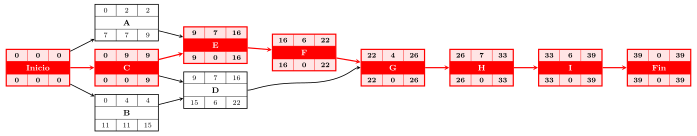

In [10]:
#| fig-cap: "Grafo Roy con las estimaciones agresivas y la cadena crítica"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [11]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

In [12]:
#| tbl-cap: "Calendario con las estimaciones agresivas (inicios más tempranos y holguras)"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
proyecto.display_calendario(datos_proyecto['duration'], grafo="roy")

Actividad,Duración,Inicio más temprano,Fin más temprano,Inicio más tardío,Fin más tardío,H total,H libre,H independiente
A,2,0,2,7,9,7,7,7
B,4,0,4,11,15,11,5,5
C,9,0,9,0,9,0,0,0
D,7,9,16,15,22,6,6,0
E,7,9,16,9,16,0,0,0
F,6,16,22,16,22,0,0,0
G,4,22,26,22,26,0,0,0
H,7,26,33,26,33,0,0,0
I,6,33,39,33,39,0,0,0


In [13]:
plan = proyecto.plan_cadena_critica(datos_proyecto, agresiva='agresiva', segura='segura', metodo='cortar_pegar')
cadena = plan.cadena
Markdown(f'Cadena crítica: **{" - ".join(cadena)}** ({plan.duracion_cadena} días).')

Cadena crítica: **C - E - F - G - H - I** (39 días).

In [14]:
#| tbl-cap: "Colchón del proyecto"
#| label: tbl-colchon
detalle_colchon(plan.margen[cadena], 'colchón del proyecto').loc[['cortar y pegar = 0,5·Σ márgenes']]

,colchón del proyecto
"cortar y pegar = 0,5·Σ márgenes","0,5·(5 + 4 + 3 + 2 + 5 + 4) = 0,5·23 = 11.5 → 12"


In [15]:
Markdown(f'Colchón del proyecto: **{plan.colchon_proyecto} días**; fecha comprometida {plan.duracion_cadena} + {plan.colchon_proyecto} = **{plan.compromiso} días**.')

Colchón del proyecto: **12 días**; fecha comprometida 39 + 12 = **51 días**.

## Apartado 2

In [16]:
display(Markdown(pregunta_2))

2. Identifique los puntos en los que una actividad que no es de la cadena desemboca en ella. Para cada uno, indique la cadena de alimentación (la más larga que llega a ese punto), dimensione su colchón de alimentación y compruebe si cabe en la holgura disponible.  

Un colchón de alimentación protege a la cadena crítica de los retrasos de un camino que desemboca en ella: se coloca en el arco por el que ese camino entra en la cadena. Se dimensiona con los márgenes de la cadena de alimentación más larga que llega a ese arco (sólo con actividades que no son de la cadena crítica). La holgura disponible es lo que puede separarse el fin de la última actividad de alimentación, en su fecha más temprana, del inicio de la actividad de la cadena.

In [17]:
#| tbl-cap: "Colchones de alimentación"
#| label: tbl-alimentacion
tabla_alimentacion(plan)

,arco,cadena de alimentación,colchón requerido,holgura disponible = inicio de la cadena − fin más temprano,"colchón adoptado = mín(requerido, disponible)"
CA1,A → E,A,"0,5·(2) = 1 → 1",9 − 2 = 7,1
CA2,D → G,B - D,"0,5·(1 + 3) = 2 → 2",22 − 16 = 6,2


## Apartado 3

In [18]:
display(Markdown(pregunta_3))

3. Programe las actividades de alimentación lo más tarde posible, con su colchón por delante de la cadena crítica. Indique el inicio de cada actividad y dibuje el diagrama de Gantt con los colchones.  

La cadena crítica se programa en sus inicios más tempranos. Las actividades de alimentación se programan hacia atrás, de la última a la primera: cada una termina cuando empieza la primera de sus sucesoras o, si la sucesora es de la cadena, cuando empieza su colchón de alimentación.

In [19]:
#| tbl-cap: "Programación lo más tarde posible de las actividades de alimentación"
#| label: tbl-alap
detalle_alap(plan)

,fin = mín(inicio de las sucesoras),inicio = fin − duración,inicio más temprano
D,mín(G − CA2: 22 − 2 = 20) = 20,20 − 7 = 13,9
B,mín(D: 13) = 13,13 − 4 = 9,0
A,mín(E − CA1: 9 − 1 = 8) = 8,8 − 2 = 6,0


In [20]:
#| tbl-cap: "Plan de cadena crítica"
#| label: tbl-plan
plan.tabla()[['agresiva', 'cadena', 'inicio', 'fin']].assign(**{'inicio más temprano': plan.inicio_temprano}).T

,A,B,C,D,E,F,G,H,I
agresiva,2,4,9,7,7,6,4,7,6
cadena,,,sí,,sí,sí,sí,sí,sí
inicio,6,9,0,13,9,16,22,26,33
fin,8,13,9,20,16,22,26,33,39
inicio más temprano,0,0,0,9,9,16,22,26,33


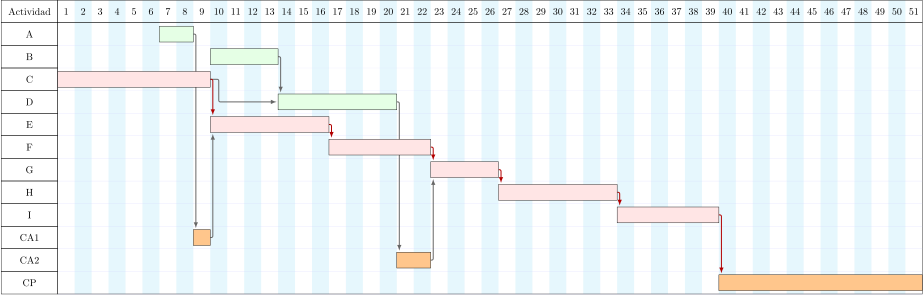

In [21]:
#| fig-cap: "Diagrama de Gantt del plan de cadena crítica: cadena en rojo, alimentación en verde, colchones en naranja"
#| label: fig-ganttCCPM
pinta_tikz(plan.gantt_tikz(params=GANTT_CC))

## Apartado 4

In [22]:
display(Markdown(pregunta_4))

4. ¿Por qué se programan las cadenas de alimentación lo más tarde posible y no en su inicio más temprano? ¿Qué se gana y qué se arriesga?  

Programar la alimentación lo más tarde posible evita comprometer recursos y dinero antes de tiempo (el gasto se retrasa, el trabajo en curso es menor y se pueden incorporar cambios con menos pérdida) y deja el margen donde protege: en el colchón, a la vista de todos, en lugar de en una holgura que se consumiría por el síndrome del estudiante. A cambio, el camino de alimentación queda sin más protección que su colchón: si se retrasa más que él, el retraso pasa a la cadena crítica y consume colchón del proyecto. Por eso se vigila el consumo de cada colchón de alimentación.